# Notebook 01: Data Inspection & Exploratory Data Analysis
## AI-Based Groundwater Level Monitoring and Forecasting System

**Objective:** Understand the CGWB Bihar groundwater telemetry dataset before building any model.

**What we'll do:**
1. Load the raw CSV and examine its structure
2. Understand what each column means
3. Analyze station coverage and data quality
4. Select the best station for modeling
5. Visualize the groundwater level time series and seasonal patterns

---

## 1. Setup & Load Data

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import os

# Set display options so we can see more data
pd.set_option('display.max_columns', 25)
pd.set_option('display.width', 120)

# Plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (14, 5), 'font.size': 11, 'figure.dpi': 100})

print('Libraries loaded successfully!')

Libraries loaded successfully!


In [2]:
# Load the raw CSV file
csv_path = os.path.join('..', 'data', 'gwl_tel_6_hourly_cgwb_br_2021_2025 (1).csv')
df = pd.read_csv(csv_path)

print(f'Dataset loaded!')
print(f'Rows: {len(df):,}')
print(f'Columns: {len(df.columns)}')

Dataset loaded!
Rows: 52,998
Columns: 21


## 2. Understand the Dataset Structure

Let's look at the first few rows and understand what each column represents.

In [3]:
# View first 5 rows
df.head()

,SlNo,Station,Agency,State LGD Code,State,District LGD Code,District,Tehsil,Block,Village,River,Basin,Tributary,Subtributary,SubSubtributary,Local River,Latitude,Longitude,RL_MSL,Data Acquisition Time,Groundwater Level Telemetry 6 Hourly (meter)
0,1,A.N. College,CGWB,10,Bihar,212,PATNA,-,-,-,-,-,-,-,-,-,25.6184,85.11,55.1,02-03-2023 00:00,-11.04
1,2,A.N. College,CGWB,10,Bihar,212,PATNA,-,-,-,-,-,-,-,-,-,25.6184,85.11,55.1,02-03-2023 06:00,-10.26
2,3,A.N. College,CGWB,10,Bihar,212,PATNA,-,-,-,-,-,-,-,-,-,25.6184,85.11,55.1,02-03-2023 12:00,-11.33
3,4,A.N. College,CGWB,10,Bihar,212,PATNA,-,-,-,-,-,-,-,-,-,25.6184,85.11,55.1,02-03-2023 18:00,-11.38
4,5,A.N. College,CGWB,10,Bihar,212,PATNA,-,-,-,-,-,-,-,-,-,25.6184,85.11,55.1,03-03-2023 00:00,-11.04


In [4]:
# Column names and data types
print('Column Names and Data Types:')
print('=' * 60)
for col in df.columns:
    print(f'  {col:<55} {df[col].dtype}')

Column Names and Data Types:
  SlNo                                                    int64
  Station                                                 str
  Agency                                                  str
  State LGD Code                                          int64
  State                                                   str
  District LGD Code                                       int64
  District                                                str
  Tehsil                                                  str
  Block                                                   str
  Village                                                 str
  River                                                   str
  Basin                                                   str
  Tributary                                               str
  Subtributary                                            str
  SubSubtributary                                         str
  Local River                      

In [5]:
# Check for missing values
print('Missing Values per Column:')
print('=' * 40)
missing = df.isnull().sum()
if missing.sum() == 0:
    print('  No missing values in any column! \u2713')
else:
    print(missing[missing > 0])

print(f'\nTotal rows with any NaN: {df.isnull().any(axis=1).sum()}')

Missing Values per Column:
  No missing values in any column! ✓

Total rows with any NaN: 0


## 3. Understanding the Groundwater Level Measurement

The key column is `Groundwater Level Telemetry 6 Hourly (meter)`.

**How to read the values:**
- `-11.04` means the water table is **11.04 meters below ground surface**
- More negative = deeper water table (water is falling)
- Less negative = shallower water table (water is rising)
- This matches our hardware sensor convention (sensor at ground level, outputs negative depth)

In [6]:
# Rename the long column for convenience
gwl_col = 'Groundwater Level Telemetry 6 Hourly (meter)'

# Statistical summary of groundwater levels
print('Groundwater Level Statistics (all stations combined):')
print('=' * 50)
print(df[gwl_col].describe())
print(f'\nNon-null readings: {df[gwl_col].notna().sum():,}')
print(f'Null readings:     {df[gwl_col].isna().sum()}')

Groundwater Level Statistics (all stations combined):
count    52998.000000
mean        -8.045251
std          3.937388
min        -29.380000
25%        -10.830000
50%         -8.260000
75%         -5.192000
max         18.010000
Name: Groundwater Level Telemetry 6 Hourly (meter), dtype: float64

Non-null readings: 52,998
Null readings:     0


In [7]:
# Parse timestamps
# Format in CSV: "02-03-2023 00:00" (DD-MM-YYYY HH:MM)
df['datetime'] = pd.to_datetime(df['Data Acquisition Time'], format='%d-%m-%Y %H:%M')

print(f'Date Range:')
print(f'  Earliest observation: {df["datetime"].min()}')
print(f'  Latest observation:   {df["datetime"].max()}')
print(f'  Span: ~{(df["datetime"].max() - df["datetime"].min()).days} days')
print(f'  Unparseable dates: {df["datetime"].isna().sum()}')

Date Range:
  Earliest observation: 2023-03-02 00:00:00
  Latest observation:   2025-12-31 18:00:00
  Span: ~1035 days
  Unparseable dates: 0


## 4. Station Analysis

The dataset contains multiple monitoring stations (wells) across Bihar. 
We need to find which stations have the most complete and reliable data.

In [8]:
# Analyze each station
station_stats = df.groupby('Station').agg(
    records=(gwl_col, 'count'),
    min_date=('datetime', 'min'),
    max_date=('datetime', 'max'),
    min_gwl=(gwl_col, 'min'),
    max_gwl=(gwl_col, 'max'),
    mean_gwl=(gwl_col, 'mean'),
    district=('District', 'first'),
).reset_index()

station_stats['days_spanned'] = (station_stats['max_date'] - station_stats['min_date']).dt.days
station_stats['positive_count'] = df.groupby('Station')[gwl_col].apply(lambda x: (x > 0).sum()).values
station_stats = station_stats.sort_values('records', ascending=False)

print(f'Total unique stations: {len(station_stats)}')
print(f'\nStation Summary (sorted by record count):')
print('=' * 100)
display_cols = ['Station', 'district', 'records', 'days_spanned', 'min_gwl', 'max_gwl', 'mean_gwl', 'positive_count']
print(station_stats[display_cols].to_string(index=False))

Total unique stations: 23

Station Summary (sorted by record count):
                                     Station   district  records  days_spanned  min_gwl  max_gwl   mean_gwl  positive_count
                                   Khagaul I      PATNA     3783          1034  -14.880   -4.690  -9.945208               0
                                A.N. College      PATNA     3772          1035  -26.030   -1.000 -11.111092               0
                                 Naubatpur I      PATNA     3768          1033  -14.000    0.020  -9.941433               1
                                    Bikram_1      PATNA     3461          1017  -11.930   -1.000  -9.179243               0
                            Patna University      PATNA     3333           994  -12.600  -10.920 -11.689946               0
                                Naubatpur Ii      PATNA     3167           936  -12.681    6.535  -6.716523             385
                                     Simri I      PATNA     257

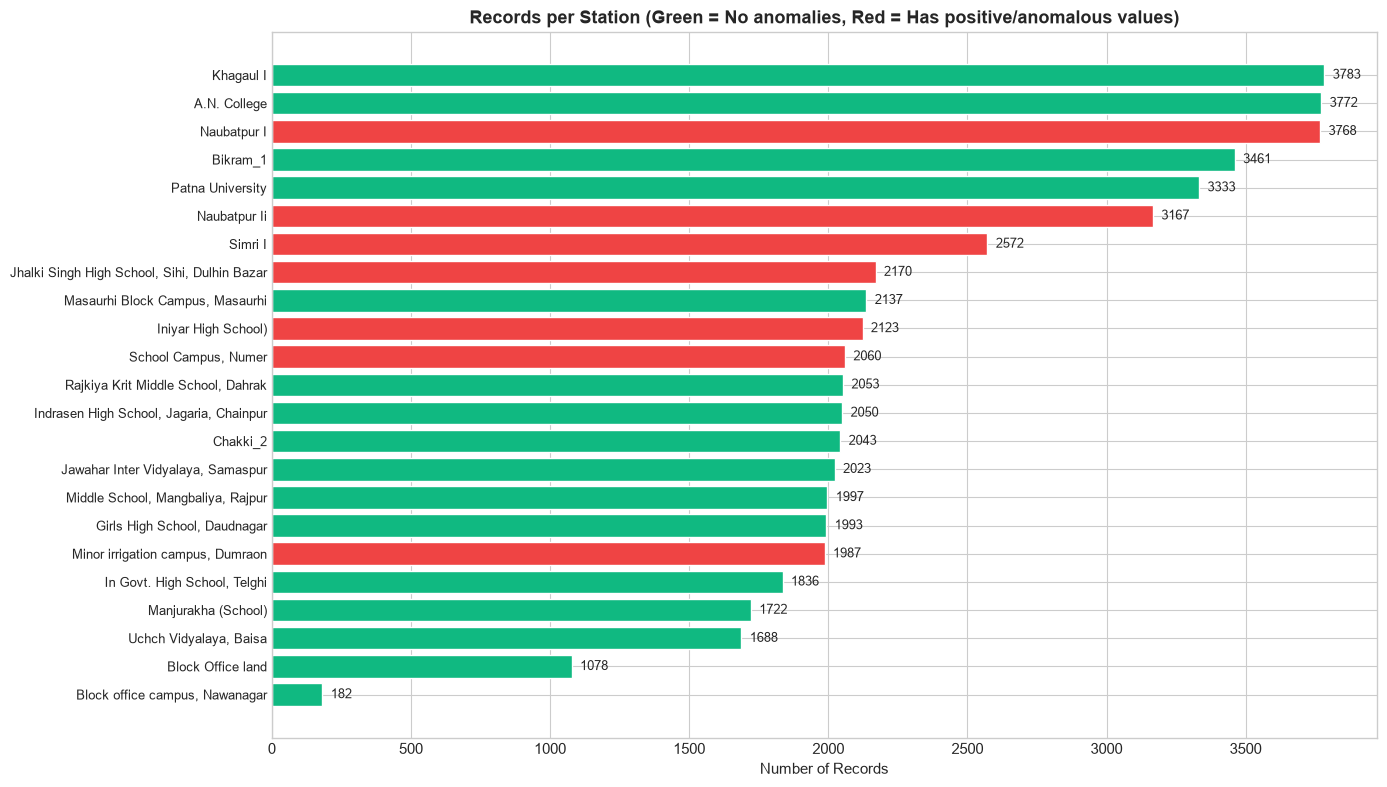

In [9]:
# Visualize station record counts
fig, ax = plt.subplots(figsize=(14, 8))

colors = ['#10B981' if p == 0 else '#EF4444' for p in station_stats['positive_count'].values]
bars = ax.barh(range(len(station_stats)), station_stats['records'].values, color=colors, edgecolor='white')
ax.set_yticks(range(len(station_stats)))
ax.set_yticklabels(station_stats['Station'].values, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Number of Records')
ax.set_title('Records per Station (Green = No anomalies, Red = Has positive/anomalous values)', fontweight='bold')

for bar, val in zip(bars, station_stats['records'].values):
    ax.text(bar.get_width() + 30, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)

plt.tight_layout()
plt.show()

## 5. District Distribution

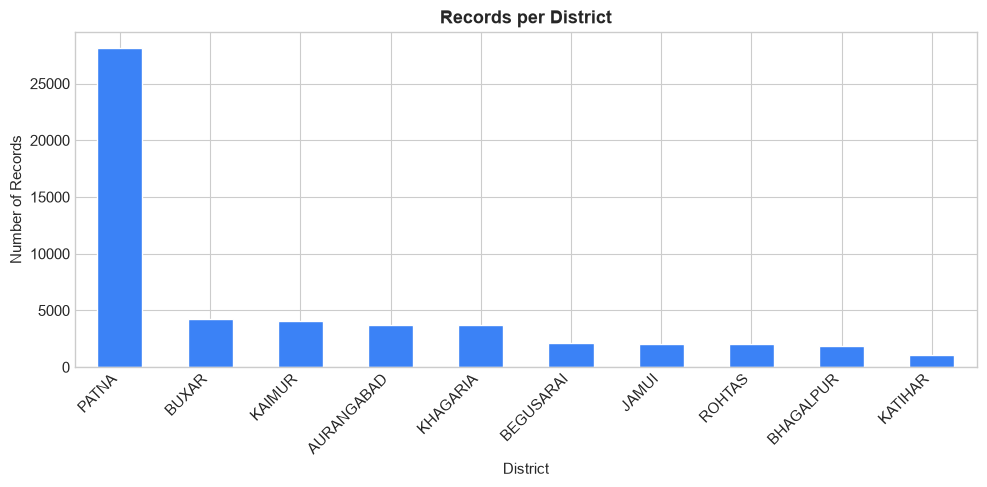

District
PATNA         28163
BUXAR          4212
KAIMUR         4103
AURANGABAD     3715
KHAGARIA       3711
BEGUSARAI      2123
JAMUI          2060
ROHTAS         1997
BHAGALPUR      1836
KATIHAR        1078
Name: count, dtype: int64


In [10]:
# How many records per district?
fig, ax = plt.subplots(figsize=(10, 5))
district_counts = df['District'].value_counts()
district_counts.plot(kind='bar', color='#3B82F6', edgecolor='white', ax=ax)
ax.set_title('Records per District', fontweight='bold')
ax.set_ylabel('Number of Records')
ax.set_xlabel('District')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print(district_counts)

## 6. Deep Dive: Top Station — Khagaul I

**Why Khagaul I?**
- Most records (3,783)
- Longest time span (1,034 days = ~2.8 years)
- **Zero** anomalous positive values
- **Zero** suspicious zeros
- Clean GWL range: -14.88 to -4.69 meters
- Located in Patna district (most monitored area)

In [11]:
# Filter to Khagaul I
station_name = 'Khagaul I'
st = df[df['Station'] == station_name].sort_values('datetime').copy()

print(f'Station: {station_name}')
print(f'  District: {st["District"].iloc[0]}')
print(f'  Latitude: {st["Latitude"].iloc[0]}, Longitude: {st["Longitude"].iloc[0]}')
print(f'  Ground Elevation (RL_MSL): {st["RL_MSL"].iloc[0]} meters above sea level')
print(f'  Records: {len(st):,}')
print(f'  Date range: {st["datetime"].min()} to {st["datetime"].max()}')
print(f'  GWL range: {st[gwl_col].min():.2f} to {st[gwl_col].max():.2f} meters')
print(f'  Mean GWL: {st[gwl_col].mean():.2f} meters')

Station: Khagaul I
  District: PATNA
  Latitude: 25.578202, Longitude: 85.048571
  Ground Elevation (RL_MSL): 56.0 meters above sea level
  Records: 3,783
  Date range: 2023-03-03 00:00:00 to 2025-12-31 00:00:00
  GWL range: -14.88 to -4.69 meters
  Mean GWL: -9.95 meters


In [12]:
# Observation frequency check
st['time_diff'] = st['datetime'].diff()

print('Time intervals between consecutive readings:')
print(st['time_diff'].describe())
print(f'\nMost common intervals:')
print(st['time_diff'].value_counts().head(5))

# Gap analysis
gaps = st[st['time_diff'] > pd.Timedelta(hours=12)]
print(f'\nGap Analysis:')
print(f'  Gaps > 12 hours: {len(gaps)}')
print(f'  Gaps > 1 day:    {(gaps["time_diff"] > pd.Timedelta(days=1)).sum()}')
print(f'  Gaps > 3 days:   {(gaps["time_diff"] > pd.Timedelta(days=3)).sum()}')
print(f'  Gaps > 7 days:   {(gaps["time_diff"] > pd.Timedelta(days=7)).sum()}')
print(f'  Largest gap:     {gaps["time_diff"].max()}')

Time intervals between consecutive readings:
count                      3782
mean     0 days 06:33:41.787414
std      0 days 06:16:44.554715
min             0 days 06:00:00
25%             0 days 06:00:00
50%             0 days 06:00:00
75%             0 days 06:00:00
max             8 days 06:00:00
Name: time_diff, dtype: object

Most common intervals:
time_diff
0 days 06:00:00    3731
1 days 00:00:00      16
1 days 06:00:00      15
2 days 06:00:00       6
3 days 06:00:00       4
Name: count, dtype: int64

Gap Analysis:
  Gaps > 12 hours: 51
  Gaps > 1 day:    35
  Gaps > 3 days:   10
  Gaps > 7 days:   1
  Largest gap:     8 days 06:00:00


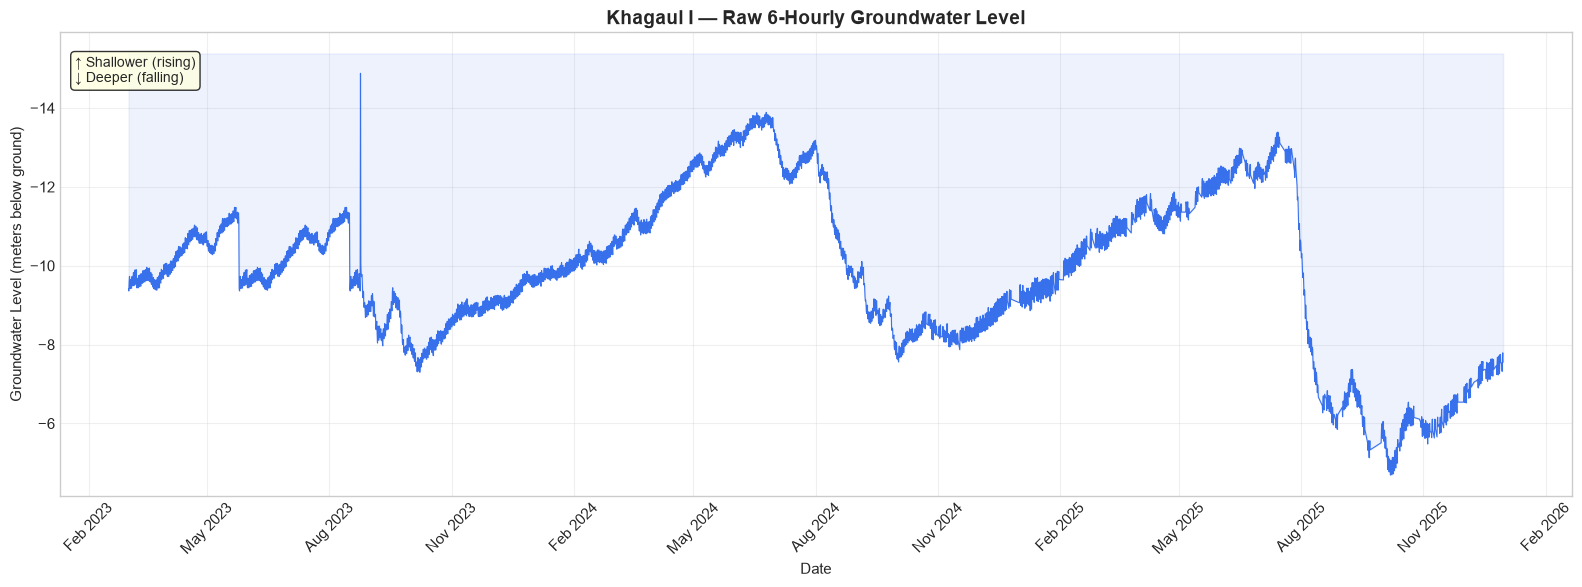

In [13]:
# Plot the raw 6-hourly time series
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(st['datetime'], st[gwl_col], color='#2563EB', linewidth=0.8, alpha=0.9)
ax.fill_between(st['datetime'], st[gwl_col], st[gwl_col].min() - 0.5,
                alpha=0.08, color='#2563EB')

ax.set_title(f'{station_name} — Raw 6-Hourly Groundwater Level', fontweight='bold', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Groundwater Level (meters below ground)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45)
ax.invert_yaxis()  # Deeper at bottom
ax.grid(True, alpha=0.3)

ax.annotate('\u2191 Shallower (rising)\n\u2193 Deeper (falling)', 
            xy=(0.01, 0.95), xycoords='axes fraction',
            fontsize=10, ha='left', va='top',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8))

plt.tight_layout()
plt.show()

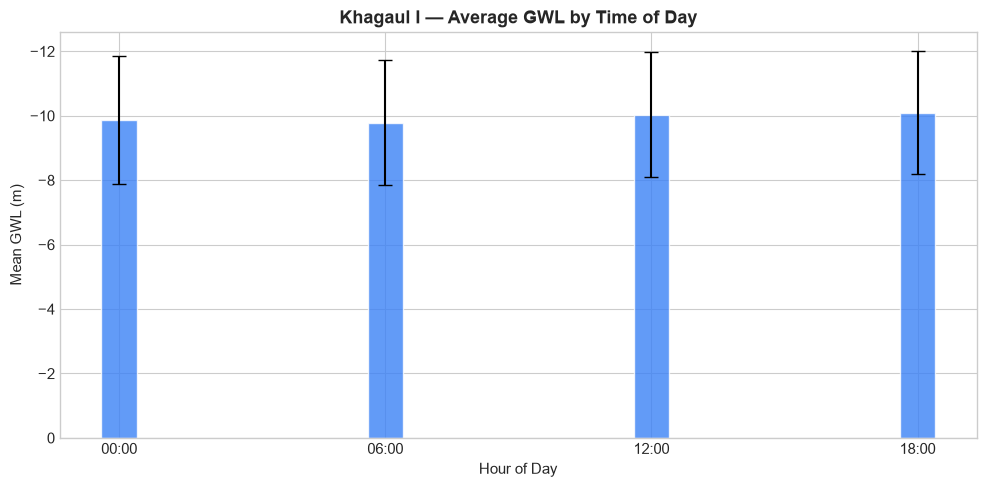

Interpretation:
  The ~0.3m daily swing is physically realistic.
  Water is shallowest in morning (06:00) after overnight recovery,
  and deepest in evening (18:00) after daytime pumping.


In [14]:
# Within-day pattern (diurnal cycle)
st['hour'] = st['datetime'].dt.hour
hourly_means = st.groupby('hour')[gwl_col].agg(['mean', 'std'])

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(hourly_means.index, hourly_means['mean'], 
       yerr=hourly_means['std'], color='#3B82F6', edgecolor='white',
       capsize=5, alpha=0.8)
ax.set_title(f'{station_name} — Average GWL by Time of Day', fontweight='bold')
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Mean GWL (m)')
ax.set_xticks(hourly_means.index)
ax.set_xticklabels([f'{h:02d}:00' for h in hourly_means.index])
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print('Interpretation:')
print('  The ~0.3m daily swing is physically realistic.')
print('  Water is shallowest in morning (06:00) after overnight recovery,')
print('  and deepest in evening (18:00) after daytime pumping.')

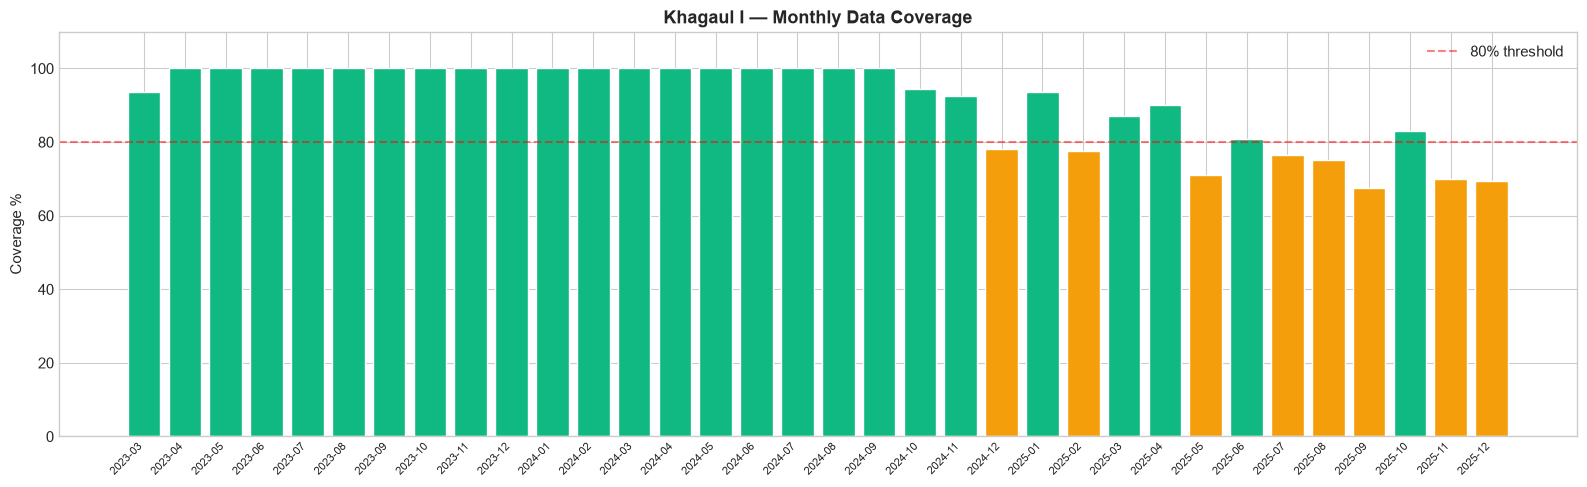

Months with >= 80% coverage: 26 / 34
Months with < 80% coverage:  8 / 34


In [15]:
# Monthly coverage analysis
st['year_month'] = st['datetime'].dt.to_period('M')
monthly = st.groupby('year_month').size().reset_index(name='readings')
monthly['expected'] = monthly['year_month'].apply(lambda x: x.days_in_month * 4)
monthly['coverage_pct'] = (monthly['readings'] / monthly['expected'] * 100).round(1)

fig, ax = plt.subplots(figsize=(16, 5))
colors = ['#10B981' if c >= 80 else '#F59E0B' if c >= 60 else '#EF4444' 
          for c in monthly['coverage_pct']]
ax.bar(range(len(monthly)), monthly['coverage_pct'], color=colors, edgecolor='white')
ax.axhline(y=80, color='red', linestyle='--', alpha=0.5, label='80% threshold')
ax.set_xticks(range(len(monthly)))
ax.set_xticklabels([str(ym) for ym in monthly['year_month']], rotation=45, ha='right', fontsize=8)
ax.set_ylabel('Coverage %')
ax.set_title(f'{station_name} — Monthly Data Coverage', fontweight='bold')
ax.set_ylim(0, 110)
ax.legend()
plt.tight_layout()
plt.show()

print(f'Months with >= 80% coverage: {(monthly["coverage_pct"] >= 80).sum()} / {len(monthly)}')
print(f'Months with < 80% coverage:  {(monthly["coverage_pct"] < 80).sum()} / {len(monthly)}')

## 7. Anomaly Check

In [16]:
# Check for anomalies across all stations
print('ANOMALY ANALYSIS (ALL STATIONS)')
print('=' * 50)

positive = df[df[gwl_col] > 0]
print(f'Rows with POSITIVE GWL (water above ground?): {len(positive)}')
if len(positive) > 0:
    print(f'  Affected stations: {positive["Station"].nunique()}')
    print(f'  Range: {positive[gwl_col].min():.3f} to {positive[gwl_col].max():.3f}')
    print(f'  These are likely SENSOR ERRORS')

print(f'\nRows with GWL = 0.0 (exactly zero): {(df[gwl_col] == 0).sum()}')
print(f'Rows with GWL > -0.5 (near surface): {(df[gwl_col] > -0.5).sum()}')
print(f'Rows with GWL < -50 (extremely deep): {(df[gwl_col] < -50).sum()}')

# Duplicate check
dupes = df.groupby(['Station', 'Data Acquisition Time']).size()
print(f'\nDuplicate (station, timestamp) pairs: {(dupes > 1).sum()}')

print(f'\n--- Khagaul I anomalies ---')
khagaul = df[df['Station'] == 'Khagaul I']
print(f'  Positive values: {(khagaul[gwl_col] > 0).sum()}')
print(f'  Zero values:     {(khagaul[gwl_col] == 0).sum()}')
print(f'  Result: CLEAN \u2713')

ANOMALY ANALYSIS (ALL STATIONS)
Rows with POSITIVE GWL (water above ground?): 418
  Affected stations: 7
  Range: 0.020 to 18.010
  These are likely SENSOR ERRORS

Rows with GWL = 0.0 (exactly zero): 60
Rows with GWL > -0.5 (near surface): 1040
Rows with GWL < -50 (extremely deep): 0

Duplicate (station, timestamp) pairs: 0

--- Khagaul I anomalies ---
  Positive values: 0
  Zero values:     0
  Result: CLEAN ✓


## 8. Seasonal Pattern Analysis

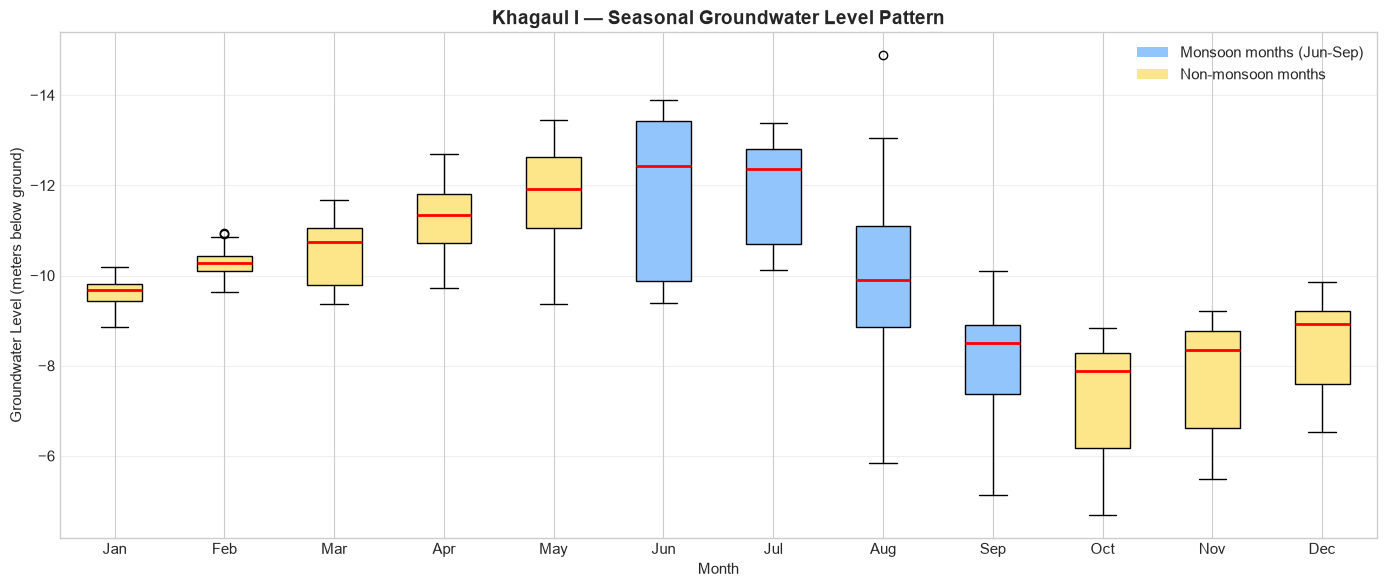

Key observation:
  Water is SHALLOWEST during/after monsoon (Jul-Oct) due to rainfall recharge.
  Water is DEEPEST in pre-monsoon summer (Apr-Jun) due to pumping + no rain.


In [17]:
# Seasonal boxplot for Khagaul I
st_monthly = st.copy()
st_monthly['month'] = st_monthly['datetime'].dt.month

fig, ax = plt.subplots(figsize=(14, 6))

month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

data_by_month = [st_monthly[st_monthly['month'] == m][gwl_col].values 
                 for m in range(1, 13)]

try:
    bp = ax.boxplot(data_by_month, tick_labels=month_names, patch_artist=True, medianprops=dict(color='red', linewidth=2))
except TypeError:
    bp = ax.boxplot(data_by_month, labels=month_names, patch_artist=True, medianprops=dict(color='red', linewidth=2))

for i, box in enumerate(bp['boxes']):
    if (i + 1) in [6, 7, 8, 9]:  # Monsoon months
        box.set_facecolor('#93C5FD')
    else:
        box.set_facecolor('#FDE68A')

ax.set_title(f'{station_name} — Seasonal Groundwater Level Pattern', fontweight='bold', fontsize=14)
ax.set_xlabel('Month')
ax.set_ylabel('Groundwater Level (meters below ground)')
ax.invert_yaxis()
ax.grid(True, alpha=0.3, axis='y')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#93C5FD', label='Monsoon months (Jun-Sep)'),
                   Patch(facecolor='#FDE68A', label='Non-monsoon months')]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.show()

print('Key observation:')
print('  Water is SHALLOWEST during/after monsoon (Jul-Oct) due to rainfall recharge.')
print('  Water is DEEPEST in pre-monsoon summer (Apr-Jun) due to pumping + no rain.')

## 9. Summary & Conclusion

### Dataset Summary
- **52,999 rows** across **23 stations** in Bihar
- Date range: **March 2023 – December 2025** (~2.8 years)
- 6-hourly telemetry (4 readings/day at 00:00, 06:00, 12:00, 18:00)
- **Zero missing values**, zero duplicate timestamps

### Selected Station: **Khagaul I** (Patna District)
- 3,783 readings over 1,034 days
- **No anomalies** (no positive values, no zeros)
- GWL range: -14.88 to -4.69 meters (meaningful variation)
- Clear seasonal pattern visible
- Only 1 gap exceeding 7 days

### Measurement Convention
- Negative values = depth below ground (matches our hardware sensor)
- More negative = deeper water table

### Next Steps → Notebook 02
- Aggregate 6-hourly to daily means
- Handle small gaps via forward-fill
- Engineer features (lags, rolling averages, trends)
- Prepare for 7-day-ahead forecasting